# 05 · Nitrate loss risk index, next 72 h (proposed replacement for the NPK model)

**What it is:** a heuristic built from published numbers, not measured nitrogen loss.
- Wetness factor: 0 below 60% water-filled pore space (WFPS), 1 at ≥ 80%, linear between (denitrification turns on sharply at 60 to 80% WFPS; HESS 8:686, 2004)
- Temperature rate: % of soil nitrate lost per saturated day; Purdue Extension: < 55 °F 1-2, 55-65 °F 2-3, > 65 °F 4-5 (midpoints used)
- Index = sum over the next 72 h of hourly (wetness × rate / 24) → **% of soil nitrate at risk in the next 3 days**

WFPS = moisture / porosity, porosity = 1 − bulk density / 2.65 (SSURGO). Computed at 10 cm (where fertilizer N sits).

In [1]:
# Setup: works locally (pip install -e . from the repo root) and on Google Colab
import sys, warnings
warnings.filterwarnings("ignore")
if "google.colab" in sys.modules:
    # Upload soilcast.zip to Google Drive (MyDrive) first
    from google.colab import drive
    drive.mount("/content/drive")
    !unzip -q -o /content/drive/MyDrive/soilcast.zip -d /content
    %cd /content/soilcast
    !pip install -q -e ".[gpu-trees]"
    sys.path.insert(0, "/content/soilcast/src")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from soilcast.config import PROCESSED, RAW, RESULTS
from soilcast.plotting import set_style, model_color, SERIES, MUTED
set_style()
pd.set_option("display.width", 160, "display.max_columns", 30, "display.precision", 3)
RESULTS.mkdir(exist_ok=True)

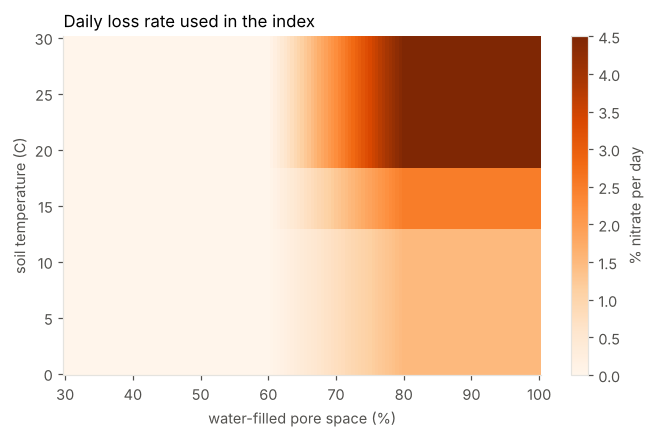

In [2]:
from soilcast.targets import nitrate_loss_rate, WFPS_ON, WFPS_FULL
wf = np.linspace(0.3, 1.0, 141); tc = np.linspace(0, 30, 121)
W, T = np.meshgrid(wf, tc)
R = nitrate_loss_rate(W * 0.5, T, np.full_like(W, 0.5))
fig, ax = plt.subplots(figsize=(7, 4))
im = ax.pcolormesh(wf * 100, tc, R, cmap="Oranges", shading="auto"); plt.colorbar(im, label="% nitrate per day")
ax.set(xlabel="water-filled pore space (%)", ylabel="soil temperature (C)", title="Daily loss rate used in the index"); ax.grid(False);

windows with risk > 0.05%: 19.4%;  90th pct 1.89%;  max 13.5%


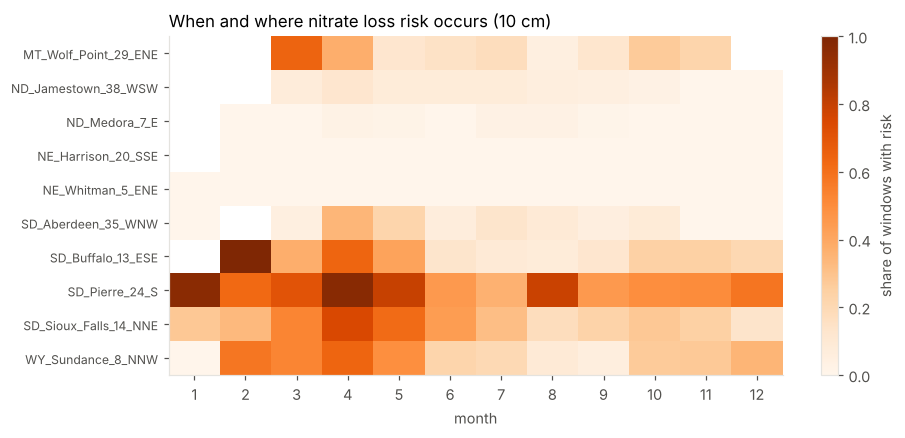

In [3]:
from soilcast.features import SENSORS, SOIL, FC72, NLRI_EXTRA, nlri_valid
from soilcast.evaluate import time_split, loso_splits, nlri_metrics
from soilcast.models import fit_predict_level
d = pd.read_parquet(PROCESSED / "features_10cm_perfect.parquet")
v = d[nlri_valid(d)]
print(f"windows with risk > 0.05%: {(v.nlri_72h > .05).mean():.1%};  90th pct {v.nlri_72h.quantile(.9):.2f}%;  max {v.nlri_72h.max():.1f}%")
m = v.assign(month=v.time_utc.dt.month).groupby(["station", "month"]).nlri_72h.apply(lambda s: (s > .05).mean()).unstack()
fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(m.values, aspect="auto", cmap="Oranges", vmin=0); plt.colorbar(im, label="share of windows with risk")
ax.set_yticks(range(len(m)), m.index, fontsize=8); ax.set_xticks(range(m.shape[1]), m.columns)
ax.set(xlabel="month", title="When and where nitrate loss risk occurs (10 cm)"); ax.grid(False);

Risk concentrates in spring (wet soils) and at fine-textured, wetter stations; the sandy Nebraska Sandhills station almost never reaches the WFPS threshold.

## Models (perfect forecasts, time split and new station)

In [4]:
base = SENSORS + SOIL + NLRI_EXTRA
fsets = {"sensors+soil": base, "sensors+soil+forecast72h": base + FC72}
tr, te = time_split(v)
preds = {"persistence": 72 * te.nl_rate_h.to_numpy()}
for fs, cols in fsets.items():
    for kind in ("linear", "gbm"):
        preds[f"{kind} | {fs}"], _ = fit_predict_level(kind, tr[cols], tr.nlri_72h, te[cols])
res = nlri_metrics(te.nlri_72h, preds, te.nl_past24)
res.to_csv(RESULTS / "05_nlri_time_split.csv", index=False); res

,model,RMSE,MAE,share_with_risk,n,AUC_any_risk,AUC_new_risk,n_new_risk
0,persistence,0.591,0.128,0.142,41850,0.868,0.500,1313
1,linear | sensors+soil,0.537,0.184,0.142,41850,0.935,0.772,1313
2,gbm | sensors+soil,0.504,0.155,0.142,41850,0.935,0.781,1313
3,linear | sensors+soil+forecast72h,0.509,0.182,0.142,41850,0.968,0.914,1313
4,gbm | sensors+soil+forecast72h,0.354,0.098,0.142,41850,0.984,0.961,1313


`AUC_new_risk` is the important column: among windows with **no risk in the past 24 h**, can the model tell which ones are about to become risky? Persistence can't (0.5).

In [5]:
cols = fsets["sensors+soil+forecast72h"]
rows = []
for st, a, b in loso_splits(v):
    if (b.nlri_72h > .05).sum() < 20: continue
    p = {"persistence": 72 * b.nl_rate_h.to_numpy()}
    p["gbm"], _ = fit_predict_level("gbm", a[cols], a.nlri_72h, b[cols])
    r = nlri_metrics(b.nlri_72h, p, b.nl_past24); r.insert(0, "station", st); rows.append(r)
loso = pd.concat(rows); loso.to_csv(RESULTS / "05_nlri_new_station.csv", index=False)
loso.pivot(index="station", columns="model", values=["AUC_any_risk", "AUC_new_risk"]).round(3)

AUC_any_risk             AUC_new_risk            
model                          gbm persistence          gbm persistence
station                                                                
MT_Wolf_Point_29_ENE         0.904       0.500        0.905         0.5
ND_Jamestown_38_WSW          0.971       0.635        0.975         0.5
ND_Medora_7_E                0.973       0.532        0.970         0.5
SD_Aberdeen_35_WNW           0.952       0.774        0.911         0.5
SD_Buffalo_13_ESE            0.965       0.907        0.883         0.5
SD_Pierre_24_S               0.992       0.942        0.939         0.5
SD_Sioux_Falls_14_NNE        0.978       0.858        0.951         0.5
WY_Sundance_8_NNW            0.977       0.841        0.951         0.5

## With real NBM forecasts (Apr to Dec 2025)

In [6]:
N = pd.read_parquet(PROCESSED / "features_10cm_nbm.parquet")
key = ["station", "time_utc"]
tp = v[v.time_utc >= "2025-04-01"]
tn = N[nlri_valid(N) & (N.time_utc >= "2025-04-01")]
tp = tp.merge(tn[key], on=key).sort_values(key).reset_index(drop=True); tn = tn.merge(tp[key], on=key).sort_values(key).reset_index(drop=True)
m = __import__("soilcast.models", fromlist=["make_model"]).make_model("gbm").fit(tr[cols], tr.nlri_72h)
real = nlri_metrics(tp.nlri_72h, {"persistence": 72 * tp.nl_rate_h, "gbm, perfect forecast": np.clip(m.predict(tp[cols]), 0, None),
                                  "gbm, NBM forecast": np.clip(m.predict(tn[cols]), 0, None)}, tp.nl_past24)
real.to_csv(RESULTS / "05_nlri_nbm_2025.csv", index=False); real

,model,RMSE,MAE,share_with_risk,n,AUC_any_risk,AUC_new_risk,n_new_risk
0,persistence,0.582,0.134,0.148,19897,0.829,0.500,876
1,"gbm, perfect forecast",0.392,0.115,0.148,19897,0.976,0.954,876
2,"gbm, NBM forecast",0.444,0.121,0.148,19897,0.945,0.868,876


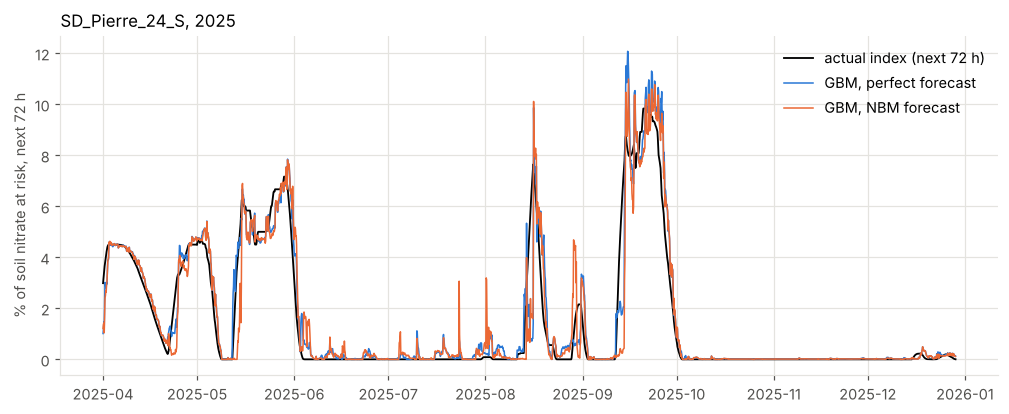

In [7]:
st_pick = (tp.assign(r=tp.nlri_72h > .05).groupby("station").r.sum().idxmax())
ex = tp.assign(perfect=np.clip(m.predict(tp[cols]), 0, None), nbm=np.clip(m.predict(tn[cols]), 0, None))
ex = ex[ex.station == st_pick]
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(ex.time_utc, ex.nlri_72h, color="black", lw=1.2, label="actual index (next 72 h)")
ax.plot(ex.time_utc, ex.perfect, color=SERIES[0], lw=1, label="GBM, perfect forecast")
ax.plot(ex.time_utc, ex.nbm, color=SERIES[1], lw=1, label="GBM, NBM forecast")
ax.set(ylabel="% of soil nitrate at risk, next 72 h", title=f"{st_pick}, 2025"); ax.legend();

## Caveats
- The index is computed from moisture and temperature, so predicting it is predicting when those cross published thresholds. It's a decision index, not validated N loss. Validation needs lab nitrate samples or N₂O flux measurements.
- SSURGO porosity doesn't always match the actual site (some readings exceed mapped porosity). A bulk density sample at Jolly Lane fixes this for the project site.